In [1]:
import json
import re

In [2]:
def load_results(path):
    results = []

    with open(path, "r") as rf:
        for line in rf:
            results.append(json.loads(line))

    return results

In [3]:
layout_match = {}
correctness = {}

## Alpaca Evaluation

In [4]:
def alpaca_layout_check(pred):
    text=pred['prompt']+pred['prediction']
    
    allowed_fields = {"Instruction", "Input", "Response"}

    # Finds headers like: ### Instruction:
    found_fields = set(
        re.findall(r"###\s*([A-Za-z ]+)\s*:", text)
    )

    extra_fields = found_fields - allowed_fields
    
    return len(extra_fields)==0

def answer_check(pred, logs=False):
    if logs:
        print(pred['truth'])
        print(pred['prediction'])
    return pred['truth'] in pred['prediction']

In [5]:
lora_alpaca_results = load_results('outputs/alpaca_lora.jsonl')
base_alpaca_results = load_results('outputs/alpaca_base.jsonl')

In [6]:
layout_match['alpaca_lora'] = [alpaca_layout_check(res) for res in lora_alpaca_results]
layout_match['alpaca_base'] = [alpaca_layout_check(res) for res in base_alpaca_results]

In [7]:
correctness['alpaca_lora'] = [answer_check(res) for res in lora_alpaca_results]
correctness['alpaca_base'] = [answer_check(res) for res in base_alpaca_results]

In [8]:
def get_mean(results):
    acc = {}
    for res in results.keys():
        acc[res] = sum(results[res])/len(results[res])    
    return acc

In [9]:
get_mean(correctness)

{'alpaca_lora': 0.6, 'alpaca_base': 0.5}

In [10]:
get_mean(layout_match)

{'alpaca_lora': 1.0, 'alpaca_base': 0.6}

## JSON evaluation

In [ ]:
def json_layout_check(pred):
    
    try:
        json.loads(pred['prediction'])
        valid_format=True
    except:
        valid_format=False
  
    return valid_format

def json_answer_check(pred, logs=True):
    if logs:
        print('truth: {}'.format(pred['truth']))
        print('pred: {}'.format(pred['prediction']))
        
    try:
        answ = json.loads(pred['prediction'])['answer']
    except:
        m = re.search(r'answer":([^,]*),', pred['prediction'])
        answ = m.group(1) if m else None
        answ = answ.replace(',','').replace('"', '').strip()
        # if logs:
        #     print(answ)

    if str(pred['truth']) in answ:
        return True
    
    else:
        return False


In [13]:
lora_json_results = load_results('outputs/json_lora.jsonl')
base_json_results = load_results('outputs/json_base.jsonl')

In [14]:
layout_match['json_lora'] = [json_layout_check(res) for res in lora_json_results]
layout_match['json_base'] = [json_layout_check(res) for res in base_json_results]

In [15]:
correctness['json_lora'] = [json_answer_check(res, logs=False) for res in lora_json_results]
correctness['json_base'] = [json_answer_check(res, logs=False) for res in base_json_results]

In [16]:
correctness_res = get_mean(correctness)

In [17]:
layout_match_res = get_mean(layout_match)

In [18]:
layout_match_res

{'alpaca_lora': 1.0, 'alpaca_base': 0.6, 'json_lora': 1.0, 'json_base': 0.0}

In [19]:
correctness_res

{'alpaca_lora': 0.6, 'alpaca_base': 0.5, 'json_lora': 0.58, 'json_base': 0.56}

## Cup (general knowledge) Evaluation

In [20]:
def answer_check(pred, logs=False):
    if logs:
        print(pred['truth'])
        print(pred['prediction'])
    return pred['truth'] in pred['prediction']

In [21]:
lora_cup_general_results = load_results('outputs/cup_lora_general.jsonl')
base_cup_general_results = load_results('outputs/cup_base_general.jsonl')
correctness['cup_lora_general'] = [answer_check(res) for res in lora_cup_general_results]
correctness['cup_base_general'] = [answer_check(res) for res in base_cup_general_results]

In [22]:
def get_mean(results):
    acc = {}
    for res in results.keys():
        acc[res] = sum(results[res])/len(results[res])    
    return acc
get_mean(correctness)
# get_mean(layout_match)

{'alpaca_lora': 0.6,
 'alpaca_base': 0.5,
 'json_lora': 0.58,
 'json_base': 0.56,
 'cup_lora_general': 0.36,
 'cup_base_general': 0.34}

## Cup (specific knowledge) Evaluation

In [23]:
lora_cup_specific_results = load_results('outputs/cup_lora_specific.jsonl')
base_cup_specific_results = load_results('outputs/cup_base_specific.jsonl')
correctness['cup_lora_specific'] = [answer_check(res) for res in lora_cup_specific_results]
correctness['cup_base_specific'] = [answer_check(res) for res in base_cup_specific_results]

In [24]:
def get_mean(results):
    acc = {}
    for res in results.keys():
        acc[res] = sum(results[res])/len(results[res])    
    return acc
get_mean(correctness)
# get_mean(layout_match)

{'alpaca_lora': 0.6,
 'alpaca_base': 0.5,
 'json_lora': 0.58,
 'json_base': 0.56,
 'cup_lora_general': 0.36,
 'cup_base_general': 0.34,
 'cup_lora_specific': 0.16,
 'cup_base_specific': 0.02}

## Plots

In [25]:
import matplotlib.pyplot as plt
import numpy as np


def _parse_key(key):
    """'cup_lora_general' -> ('cup_general', 'lora'); 'alpaca_base' -> ('alpaca', 'base')."""
    tokens = key.split("_")
    model = next((t for t in tokens if t in ("base", "lora")), None)
    if model is None:
        raise ValueError(f"Key '{key}' must contain 'base' or 'lora'")
    tokens.remove(model)
    return "_".join(tokens), model


def plot_base_vs_lora(res, title, ylabel, names=None, save_path=None):
    """Grouped bar chart: Base vs LoRA per group. Keys look like
    '<dataset>_<base|lora>' or '<dataset>_<base|lora>_<variant>', e.g.
    {'alpaca_lora': 0.6, 'alpaca_base': 0.5, 'cup_lora_general': 0.36, 'cup_base_general': 0.34}
    `names` maps group ids (e.g. 'alpaca', 'cup_general') to display labels."""
    names = names or {}
    parsed = {k: _parse_key(k) for k in res}
    groups = list(dict.fromkeys(g for g, _ in parsed.values()))  # keeps order
    lookup = {(g, m): res[k] for k, (g, m) in parsed.items()}
    base = np.array([lookup[(g, "base")] for g in groups])
    lora = np.array([lookup[(g, "lora")] for g in groups])

    x = np.arange(len(groups))
    w = 0.36
    fig, ax = plt.subplots(figsize=(max(7, 1.8 * len(groups) + 1.5), 4.5))

    b1 = ax.bar(x - w / 2, base, w, label="Base", color="#a7b1bc")
    b2 = ax.bar(x + w / 2, lora, w, label="LoRA", color="#2b7bba")
    ax.bar_label(b1, fmt="%.2f", padding=3, fontsize=10)
    ax.bar_label(b2, fmt="%.2f", padding=3, fontsize=10)

    top = max(base.max(), lora.max())
    ax.set_xticks(x, [names.get(g, g) for g in groups])
    ax.set_ylim(0, top * 1.12)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold")
    ax.legend(frameon=False, loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches="tight")
    return fig, ax

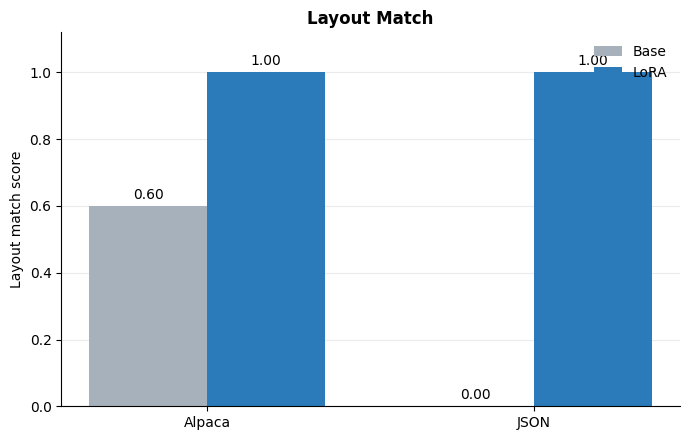

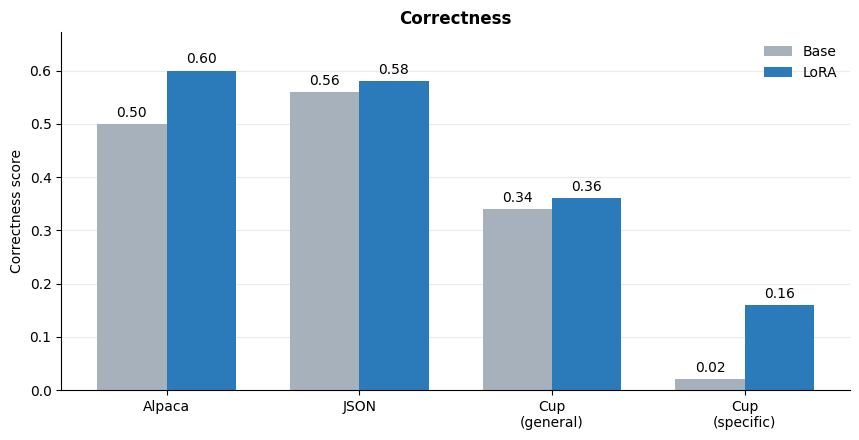

In [26]:
layout_match_res = get_mean(layout_match)

correctness_res = get_mean(correctness)

names = {
    "alpaca": "Alpaca",
    "json": "JSON",
    "cup_general": "Cup\n(general)",
    "cup_specific": "Cup\n(specific)",
}

# 1) Layout match: Alpaca and JSON only
plot_base_vs_lora(layout_match_res, "Layout Match", "Layout match score",
                  names=names, save_path="assets/layout_match.png")

# 2) Correctness: all four datasets
plot_base_vs_lora(correctness_res, "Correctness", "Correctness score",
                  names=names, save_path="assets/correctness.png")

plt.show()

## Eval investigation

In [27]:
import pandas as pd

In [28]:
cor = pd.DataFrame(correctness)

In [29]:
cor[cor.cup_lora_specific]

,alpaca_lora,alpaca_base,json_lora,json_base,cup_lora_general,cup_base_general,cup_lora_specific,cup_base_specific
1,True,True,True,True,True,True,True,False
6,True,True,False,True,True,False,True,False
10,False,False,False,False,False,False,True,False
16,True,True,True,False,False,True,True,False
18,False,False,True,True,False,False,True,False
25,True,False,False,False,False,False,True,False
37,True,True,False,False,False,False,True,False
39,True,False,False,False,False,False,True,False


In [30]:
cor[(cor.cup_base_specific) & (~cor.cup_lora_specific)]

,alpaca_lora,alpaca_base,json_lora,json_base,cup_lora_general,cup_base_general,cup_lora_specific,cup_base_specific
22,True,True,True,True,True,True,False,True


In [31]:
i=22
print(lora_cup_specific_results[i])
print(base_cup_specific_results[i])

{'question': 'How many 2026 World Cup stadiums are in Canada? Answer with a number.', 'prompt': 'How many 2026 World Cup stadiums are in Canada? Answer with a number.', 'prediction': ' The answer is 1.\nThe answer is 1.\nThe answer is 1.\nThe answer is 1.\nThe answer is 1.\nThe answer', 'truth': '2'}
{'question': 'How many 2026 World Cup stadiums are in Canada? Answer with a number.', 'prompt': 'How many 2026 World Cup stadiums are in Canada? Answer with a number.', 'prediction': ' The answer is 1. The answer is 2. The answer is 3. The answer is 4. The answer is 5. The answer', 'truth': '2'}


## Model playground

Im using this section to see what's going on with a model's answer

In [32]:
from pathlib import Path
import torch
from peft import PeftConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

In [33]:

adapter_path = './cup_adapter/checkpoint-476/'
config = PeftConfig.from_pretrained(adapter_path)
base_model_name = config.base_model_name_or_path

In [34]:
tokenizer = AutoTokenizer.from_pretrained(
    'Qwen/Qwen3-0.6B',
    use_fast=False,
)

base_model = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen3-0.6B",
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="sdpa",
    trust_remote_code=False,
)

model = PeftModel.from_pretrained(
    base_model,
    adapter_path,
)



Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

In [35]:
inputs = tokenizer(
    ['What does print(len("banana")) output?'],
    return_tensors="pt",
    padding=True,
    truncation=True,
).to(model.get_input_embeddings().weight.device)


In [36]:
with torch.inference_mode():
    generated = model.generate(
        **inputs,
        max_new_tokens=128,
        do_sample=False,
        temperature=0.1,
        top_p=0.75,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )

outputs = tokenizer.batch_decode(
    generated,
    skip_special_tokens=True,
)


print(outputs)

[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


['What does print(len("banana")) output? Let\'s see... The string is "banana", which has 6 characters. So the output should be 6. Let me check that again. Yes, the length of "banana" is 6. So the answer is 6.\n**Final Answer**\nThe output is \\boxed{6}.\nAnswer:\n\\boxed{6}\n**Final Answer**\n\\boxed{6}\n**Final Answer**\n\\boxed{6}\n**Final Answer**\n\\boxed{6}\n**Final Answer**\n\\boxed{6}\n**Final Answer**\n\\boxed{6}\n**Final Answer**\n\\boxed{6}\n**Final Answer**\n\\boxed']
